In [1]:
import re
import os
import jpype
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve
import nltk
from nltk.corpus import stopwords

ZEMBEREK_PATH="zemberek-full.jar"

In [2]:
os.environ["JAVA_HOME"]=r"C:\Program Files\Java\jdk-17"
if not jpype.isJVMStarted():
    jpype.startJVM(
        jpype.getDefaultJVMPath(),
        "-Xmx2g",
        f"-Djava.class.path={ZEMBEREK_PATH}",
        ignoreUnrecognized=True
    )

In [3]:
nltk.download('stopwords')
TurkishSentenceExtractor=jpype.JClass('zemberek.tokenization.TurkishSentenceExtractor')
TurkishMorphology=jpype.JClass('zemberek.morphology.TurkishMorphology')
TurkishSpellChecker=jpype.JClass('zemberek.normalization.TurkishSpellChecker')
TurkishTokenizer=jpype.JClass('zemberek.tokenization.TurkishTokenizer')

extractor=TurkishSentenceExtractor.DEFAULT
morphology=TurkishMorphology.createWithDefaults()
tokenizer=TurkishTokenizer.ALL
spell=TurkishSpellChecker(morphology)
stop_words=nltk.corpus.stopwords.words('turkish')
text_count=0

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\zynpe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
def preprocess_text(text):
    if isinstance(text,list):
        if len(text)>0:
            text=text[0]
        else:
            return ''
        
    text=re.sub(r'\b\d+\b','',text)
    text=re.sub(r'[^\w\s]','',text)
    text=text.lower()
    
    tokens=tokenizer.tokenize(text)
    process_word=[]
    for token in tokens:
        word=str(token.getText())
        if word.isalpha() and word not in stop_words:
            analysis=morphology.analyze(word)
            analysis_list=list(analysis)
            if len(analysis_list)>0:
                best_analysis=analysis_list[0]
                proper_noun=str(best_analysis.getPos())
                if "ProperNoun" in proper_noun:
                    process_word.append(word)
                    continue
                lemmatization=str(best_analysis.getStems().get(0))
                if proper_noun=='Verb' and not word.startswith(lemmatization):
                    process_word.append(word)
                else:
                    process_word.append(lemmatization)
            else:
                process_word.append(word)
    return " ".join(process_word)

In [8]:
#ornek = "Yapay zeka algoritmaları Ankara'da geliştirildi."
#print(preprocess_text(ornek))

In [5]:
df=pd.read_csv('data/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['category'].value_counts())
display(df.head(2))

Toplam makale sayısı:6430


category
tarih                   1498
saglik                  1497
bilgisayar_bilimleri    1495
finans                  1495
spor                     445
Name: count, dtype: int64

,category,journal,title,abstract
0,bilgisayar_bilimleri,adyujsci,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,Bu çalışmada iki problem incelenmiştir. Genel ...
1,bilgisayar_bilimleri,adyujsci,CMS Açık Veri ile Eğitici Higgs Çalışması,"Kompakt Müon Solenoid (CMS) Deneyi, CERN’in Bü..."


In [6]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess_text)
display(df[['full_text','processed_text']].head(2))

,full_text,processed_text
0,Yansımalı Banach Uzaylarda Operatörlerin Çarpı...,yansı banach uzay operatör çarpım surjektiv ss...
1,CMS Açık Veri ile Eğitici Higgs Çalışması. Kom...,cms açık veri eğit higgs çalış kompakt müon so...


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'],df['category'],test_size=0.2,random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,1),min_df=2, max_df=0.85, sublinear_tf=True)
x_train_vectorized=vectorizer.fit_transform(x_train)
x_test_vectorized=vectorizer.transform(x_test)

model=LogisticRegression(C=0.5, class_weight='balanced', random_state=42, max_iter=1000)
model.fit(x_train_vectorized, y_train)
y_pred=model.predict(x_test_vectorized)
accuracy=accuracy_score(y_test,y_pred)
print(f"Model Doğruluk Oranı %{accuracy * 100:.2f}\n")
print('SINIFLANDIRMA BAŞARI RAPORU: \n')
print(classification_report(y_test, y_pred,zero_division=0))

In [1]:
ornek="""Derin Öğrenme Modelleri Kullanılarak Türkçe Doğal Dil İşleme Süreçlerinde Duygu Analizi ve Sınıflandırma Başarısının Artırılması. Bu çalışmada, sosyal medya verileri ve akademik makaleler üzerinde duygu analizi yapmak amacıyla önişleme adımları ve transformer tabanlı derin öğrenme mimarileri (BERT, RoBERTa) karşılaştırmalı olarak incelenmiştir. Elde edilen deneysel sonuçlar, kelime vektör uzayı optimizasyonlarının ve dikkat mekanizmalarının metin sınıflandırma doğruluğunu önemli ölçüde artırdığını ve kategorik hata oranlarını minimum seviyeye indirdiğini göstermektedir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

NameError: name 'preprocess_text' is not defined

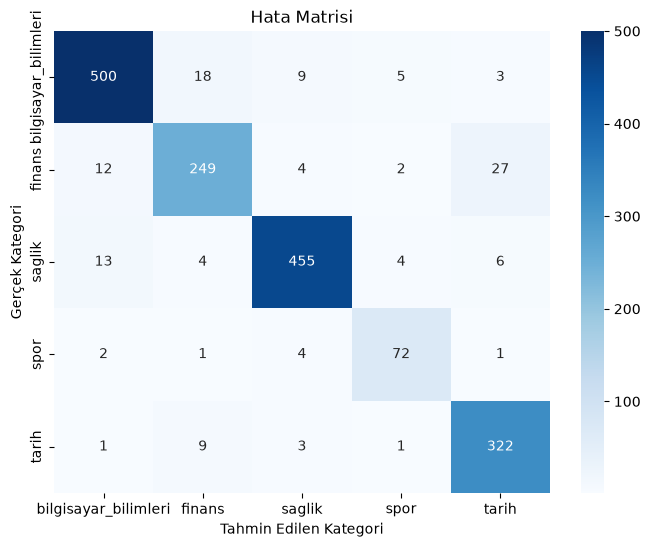

In [65]:
y_pred = model.predict(x_test_vectorized)
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model.classes_, 
            yticklabels=model.classes_)
plt.title('Hata Matrisi')
plt.xlabel('Tahmin Edilen Kategori')
plt.ylabel('Gerçek Kategori')
plt.show()

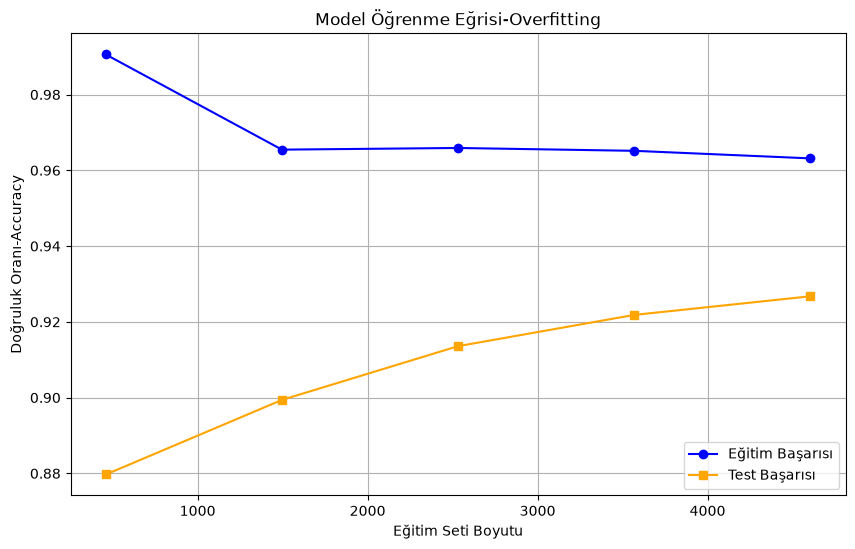

In [73]:
train_sizes, train_scores, test_scores = learning_curve(
    model,x_train_vectorized,y_train,cv=3,scoring='accuracy',train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi-Overfitting')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı-Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [66]:
ornek="""Enflasyon Oranlarının ve Döviz Kuru Dalgalanmalarının Borsa Piyasası Üzerindeki Etkisi. Bu araştırmada, makroekonomik değişkenlerden biri olan enflasyon ve döviz kurlarındaki hareketliliğin sermaye piyasaları ve hisse senedi getiri oranları üzerindeki yansımaları ampirik yöntemlerle analiz edilmiştir. Sonuçlar, yüksek enflasyon dönemlerinde yatırımcıların portföylerini korumak amacıyla alternatif finansal araçlara yöneldiğini göstermektedir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.3618
finans -> Skor: 3.4575
saglik -> Skor: -0.8758
spor -> Skor: -1.3572
tarih -> Skor: -0.8626
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- alternatif: 0.1413
- amac: 0.0739
- ampirik: 0.1797
- analiz: 0.0726
- araç: 0.1336
- araştırma: 0.0935
- borsa: 0.1752
- dalgalan: 0.2035
- değişken: 0.1235
- dönem: 0.1093
- döviz: 0.3256
- ed: 0.0491
- enflasyon: 0.3955
- etki: 0.0707
- finansal: 0.1408
- getiri: 0.1854
- göster: 0.0770
- hareket: 0.1189
- hiss: 0.1884
- koru: 0.1271
- kur: 0.1058
- kuru: 0.1671
- makroekonomik: 0.2088
- oran: 0.1845
- piyasa: 0.2410
- portföy: 0.2130
- sened: 0.2003
- sermaye: 0.1472
- sonuçla: 0.1059
- yansı: 0.1423
- yatırım: 0.1680
- yönel: 0.1850
- yöntem: 0.0711
- yüksek: 0.0827
- üzer: 0.1661
Test Edilen Cümle: 'Enflasyon Oranlarının ve Döviz Kuru Dalgalanmalarının Borsa Piyasası Üzerindeki Etkisi. Bu araştırmada, makroekonomik değişkenlerden biri olan enflasyon ve döviz kurlarındaki hareketliliğin serm

In [16]:
Başlık: Tip 2 Diyabet Hastalarında Farmakolojik Tedaviye Ek Olarak Uygulanan Diyet Programlarının Glisemik Kontrole Etkisi
Özet: Bu klinik çalışmada, tip 2 diyabet tanısı konulmuş hastaların kan glikoz düzeylerinin düzenlenmesinde tıbbi beslenme tedavisinin ve diyet uyumunun önemi değerlendirilmiştir. Araştırma sonucunda, hastaların metabolik parametrelerinin iyileşmesinde ve HbA1c seviyelerinin düşürülmesinde bireyselleştirilmiş diyet programlarının kritik bir rol oynadığı tespit edilmiştir.

SyntaxError: invalid syntax (2632031052.py, line 1)

In [67]:
ornek="""Başlık: Tip 2 Diyabet Hastalarında Farmakolojik Tedaviye Ek Olarak Uygulanan Diyet Programlarının Glisemik Kontrole Etkisi
Özet: Bu klinik çalışmada, tip 2 diyabet tanısı konulmuş hastaların kan glikoz düzeylerinin düzenlenmesinde tıbbi beslenme tedavisinin ve diyet uyumunun önemi değerlendirilmiştir. Araştırma sonucunda, hastaların metabolik parametrelerinin iyileşmesinde ve HbA1c seviyelerinin düşürülmesinde bireyselleştirilmiş diyet programlarının kritik bir rol oynadığı tespit edilmiştir."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.0189
finans -> Skor: -0.6554
saglik -> Skor: 2.9074
spor -> Skor: -0.9022
tarih -> Skor: -1.3308
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- araştır: 0.0716
- başlık: 0.1634
- besle: 0.1503
- bir: 0.0405
- bireysel: 0.1493
- değerlendir: 0.0704
- diyabet: 0.3079
- diyet: 0.4181
- düzenle: 0.1172
- düzey: 0.0921
- düşür: 0.1568
- ed: 0.0456
- ek: 0.1168
- etki: 0.0658
- farmakolojik: 0.2091
- glikoz: 0.2430
- glisemik: 0.2388
- hasta: 0.1905
- iyi: 0.0942
- kan: 0.1383
- klinik: 0.1164
- kon: 0.1181
- kontrol: 0.1036
- kritik: 0.1427
- metabolik: 0.1857
- oyna: 0.1330
- parametre: 0.1144
- program: 0.1842
- rol: 0.1055
- seviye: 0.1190
- sonuc: 0.0819
- tanı: 0.1023
- tedavi: 0.1748
- tespit: 0.0870
- tip: 0.1928
- tıbbi: 0.1514
- uygula: 0.0676
- uyum: 0.1252
- çalış: 0.0400
- önem: 0.0636
- özet: 0.1784
Test Edilen Cümle: 'Başlık: Tip 2 Diyabet Hastalarında Farmakolojik Tedaviye Ek Olarak Uygulanan Diyet Programlarının Glisemik Kontr

In [68]:
ornek="""Profesyonel Futbolcularda Maç İçi Yüksek Şiddetli Koşu Performanslarının Sezon İçindeki Değişimi. Bu çalışmada, profesyonel futbol liginde forma giyen sporcuların müsabaka esnasındaki aerobik ve anaerobik performans parametreleri GPS takip sistemleri aracılığıyla incelenmiştir. Elde edilen bulgular, oyuncuların yüksek şiddetli koçluk reaksiyonlarının ve sprint mesafelerinin maçın dakikalarına göre nasıl değiştiğini ve antrenman yüklerinin performans üzerindeki doğrudan etkilerini ortaya koymaktadır."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: 0.5549
finans -> Skor: -0.6052
saglik -> Skor: -0.5799
spor -> Skor: 1.9836
tarih -> Skor: -1.3534
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- aerobik: 0.1738
- anaerobik: 0.1672
- antrenman: 0.1608
- aracılığıyla: 0.1314
- bulgula: 0.0885
- dakika: 0.1408
- değiş: 0.0949
- değişim: 0.0975
- doğrudan: 0.1249
- ed: 0.0406
- el: 0.0633
- esna: 0.2065
- etki: 0.0586
- form: 0.0920
- futbol: 0.2588
- giy: 0.2065
- gps: 0.1954
- göre: 0.0651
- ince: 0.0654
- koy: 0.0931
- koç: 0.2094
- koşu: 0.1862
- lig: 0.1722
- maç: 0.3175
- mesafe: 0.1457
- müsabaka: 0.1714
- orta: 0.0634
- oyun: 0.1630
- parametre: 0.1018
- performans: 0.2023
- profesyonel: 0.2393
- reaksiyon: 0.1399
- sezon: 0.1755
- sistem: 0.0825
- sporcu: 0.1401
- sprint: 0.2065
- takip: 0.1157
- yük: 0.1223
- yüksek: 0.1159
- çalış: 0.0356
- üzer: 0.0813
- şiddet: 0.2093
Test Edilen Cümle: 'Profesyonel Futbolcularda Maç İçi Yüksek Şiddetli Koşu Performanslarının Sezon İçindeki Değiş

bilgisayar_bilimleri -> Skor: 2.2670
finans -> Skor: 0.0785
saglik -> Skor: -0.4259
spor -> Skor: -1.1026
tarih -> Skor: -0.8170
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- adım: 0.1761
- akademik: 0.1479
- amac: 0.0659
- analiz: 0.1096
- artır: 0.1873
- başarı: 0.1119
- bert: 0.2429
- deney: 0.1052
- derin: 0.2480
- dikkat: 0.1058
- dil: 0.1346
- doğal: 0.1305
- doğru: 0.0968
- duygu: 0.2469
- ed: 0.0438
- el: 0.0682
- göster: 0.0687
- hata: 0.1360
- ince: 0.0704
- indir: 0.1667
- karşılaştır: 0.0893
- kategorik: 0.2170
- kelim: 0.1910
- kullan: 0.0524
- makale: 0.1019
- medya: 0.1548
- mekanizma: 0.1337
- metin: 0.1589
- mimari: 0.1761
- minimum: 0.1650
- model: 0.0921
- optimizasyon: 0.1517
- oran: 0.0972
- seviye: 0.1141
- sonuçla: 0.0944
- sosyal: 0.1057
- süreç: 0.1053
- sınıf: 0.1808
- taban: 0.1272
- türk: 0.0989
- uzay: 0.1637
- vektör: 0.1676
- veri: 0.0688
- yap: 0.0586
- çalış: 0.0383
- ölçü: 0.1076
- önem: 0.0610
- önişlem: 0.2429
- öğren: 0.2292
- üzeri

In [71]:
ornek="""Osmanlı Devleti’nin Son Döneminde Taşra Teşkilatında Yapılan İdari Reformlar ve Vergi Toplama Mekanizmaları
Bu araştırmada, 19. yüzyılın ikinci yarısında merkezi otoriteyi güçlendirmek amacıyla hayata geçirilen idari ve mali düzenlemelerin Anadolu'daki yansımaları birinci el arşiv belgeleri ışığında incelenmiştir. Dönemin salnameleri ve şer'iye sicilleri taranarak, mukataa gelirlerinin dönüşümü, vergi muafiyetleri ve yerel idarecilerin merkezi hükümetle olan ilişkileri tarihsel eleştiri yöntemiyle analiz edilmiştir. Elde edilen bulgular, tanzimat sonrası bürokratik dönüşümün kırsal kesimdeki sosyo-ekonomik yapılara etkilerini aydınlatmaktadır."""
islenen_ornek=[preprocess_text(ornek)]
ornek_vectorized=vectorizer.transform(islenen_ornek)
tahmin=model.predict(ornek_vectorized)
skorlar = model.decision_function(ornek_vectorized)
for sinif, skor in zip(model.classes_, skorlar[0]):
    print(f"{sinif} -> Skor: {skor:.4f}")

feature_names = vectorizer.get_feature_names_out()
non_zero_indices = ornek_vectorized.nonzero()[1]

print("Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:\n")
for idx in non_zero_indices:
    kelime = feature_names[idx]
    agirlik = ornek_vectorized[0, idx]
    print(f"- {kelime}: {agirlik:.4f}")
print(f"Test Edilen Cümle: '{ornek}'")
print(f"Modelin tahmini kategorisi: {tahmin[0]}")

bilgisayar_bilimleri -> Skor: -0.5135
finans -> Skor: 0.8396
saglik -> Skor: -0.8286
spor -> Skor: -1.1227
tarih -> Skor: 1.6253
Modelin metinde yakaladığı kelimeler ve TF-IDF ağırlıkları:

- amac: 0.0589
- anadolu: 0.1445
- analiz: 0.0578
- araştırma: 0.0745
- arşiv: 0.1259
- aydınlat: 0.1445
- belge: 0.1293
- birinci: 0.1097
- bulgula: 0.0852
- bürokratik: 0.1832
- devlet: 0.0893
- döne: 0.0812
- dönem: 0.0871
- dönüşüm: 0.1834
- düzenle: 0.1004
- ed: 0.0662
- el: 0.1031
- eleştiri: 0.1416
- etki: 0.0563
- gelir: 0.1408
- geçir: 0.1073
- güçlen: 0.1341
- hayat: 0.1037
- hükümet: 0.1276
- idare: 0.1452
- idari: 0.1579
- ikinci: 0.1125
- ilişki: 0.0698
- ince: 0.0629
- kes: 0.1269
- kır: 0.1291
- mali: 0.1410
- mekanizma: 0.1194
- merkezi: 0.2146
- muafiyet: 0.2228
- osmanlı: 0.1034
- otorite: 0.1568
- reform: 0.1459
- salname: 0.2228
- sicil: 0.2169
- son: 0.0743
- sonra: 0.0658
- sosyoekonomik: 0.1506
- tanzimat: 0.1817
- tara: 0.1062
- tarih: 0.0772
- taşra: 0.1863
- teşkilat: 0.159

In [8]:
df=pd.read_csv('data2/dataset.csv')
print(f'Toplam makale sayısı:{len(df)}')
display(df['category'].value_counts())
display(df.head(2))

['category', 'journal', 'title', 'abstract', 'full_text', 'processed_text']

In [ ]:
df['full_text']=df['title'].fillna('')+". "+df['abstract'].fillna('')
df['processed_text']=df['full_text'].apply(preprocess_text)
display(df[['full_text','processed_text']].head(2))

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df['processed_text'],df['category'],test_size=0.2,random_state=42)
vectorizer=TfidfVectorizer(ngram_range=(1,1),min_df=2, max_df=0.85, sublinear_tf=True)
x_train_vectorized=vectorizer.fit_transform(x_train)
x_test_vectorized=vectorizer.transform(x_test)

model=LogisticRegression(C=0.5, class_weight='balanced', random_state=42, max_iter=1000)
model.fit(x_train_vectorized, y_train)
y_pred=model.predict(x_test_vectorized)
accuracy=accuracy_score(y_test,y_pred)
print(f"Model Doğruluk Oranı %{accuracy * 100:.2f}\n")
print('SINIFLANDIRMA BAŞARI RAPORU: \n')
print(classification_report(y_test, y_pred,zero_division=0))

In [ ]:
y_pred = model.predict(x_test_vectorized)
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=model.classes_, 
            yticklabels=model.classes_)
plt.title('Hata Matrisi')
plt.xlabel('Tahmin Edilen Kategori')
plt.ylabel('Gerçek Kategori')
plt.show()

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    model,x_train_vectorized,y_train,cv=3,scoring='accuracy',train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1
)
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_mean, label='Eğitim Başarısı', marker='o', color='blue')
plt.plot(train_sizes, test_mean, label='Test Başarısı', marker='s', color='orange')

plt.title('Model Öğrenme Eğrisi-Overfitting')
plt.xlabel('Eğitim Seti Boyutu')
plt.ylabel('Doğruluk Oranı-Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()